# Finding Bragg disks in simulated CBED patterns with Spotiflow

This notebook tests how well the pretrained [Spotiflow](https://github.com/weigertlab/spotiflow) model finds the Bragg disks in simulated convergent-beam electron diffraction (CBED) patterns, at probe semi-angles **1, 2 and 4 mrad** and thicknesses **20 and 40 Å**.

Each simulation provides three arrays:

| array | meaning | used for |
|---|---|---|
| `dataMeas` | simulated measured pattern | detection |
| `dataProbe` | probe aperture; every Bragg disk is a shifted copy of it | detection (disk radius, templates) |
| `dataPots` | projected potential in reciprocal space; peaks at the Bragg positions | ground truth only |

**Sections**

1. **One pattern** (1 mrad, 20 Å): linear vs log intensity.
2. **Ground truth**: spot positions from `dataPots`, and which of them are visible in the measurement.
3. **Spotiflow model and scoring**, shared by everything below.
4. **One Spotiflow pipeline per angle** with settings shared by all materials, at 20 and 40 Å.
5. **BW-tuned settings**: the same pipelines with every setting tuned on BW.
6. **Other pretrained models**: the BW-tuned inputs with a different Spotiflow model per angle.

**Main result (BW).** At 1 mrad the disks are small and separate, and Spotiflow on the log image finds all visible spots at both thicknesses. At 2 and 4 mrad the disks touch or overlap, and Spotiflow only works on an edge-based *ring correlation* map. With the shared settings it finds 23–39 % of the visible spots at 2 mrad and 7–13 % at 4 mrad; with the BW-tuned settings 78–86 % and 20–30 %. The BW-tuned settings were chosen on 40 Å, so their 20 Å rows are the fair check, and they hold there. Other pretrained Spotiflow models change the balance between found spots and false detections (section 6), but none of them solves 4 mrad.

All numbers quoted in the text are for **BW** (`MATERIAL_INDEX = 1`). Plots use colour-blind-safe Okabe-Ito colours, and every category also has its own marker shape.

In [1]:
import glob
import logging

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LogNorm
from scipy.ndimage import gaussian_filter, maximum_filter
from skimage.feature import peak_local_max
from skimage.filters import sobel
from spotiflow.model import Spotiflow
from spotiflow.utils import normalize
from spotiflow.utils.matching import points_matching

logging.getLogger("spotiflow.model.spotiflow").setLevel(logging.WARNING)  # hide Spotiflow's per-prediction INFO messages

/home/ubuntu/micromamba/envs/spotiflow/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
root = "/mnt/data/DINOV3/dinov3/dummy_data/selected_folders"
MATERIAL_INDEX = 1  # which material folder to use (1 = BW)

folder = sorted(glob.glob(f"{root}/*"))[MATERIAL_INDEX]
meta = pd.read_pickle(f"{folder}/simulation_dataframe.pkl")
material = meta["pretty_formula"].iloc[0]

# scoring
cutoff = 3   # px: a prediction is correct if it is within this distance of a ground-truth spot
near_r = 5   # px: a false detection 3-5 px from a missed spot is counted as "near a real spot"

# Okabe-Ito colours (colour-blind safe)
BLUE, SKY, ORANGE, YELLOW = "#0072B2", "#56B4E9", "#E69F00", "#F0E442"


def load_slice(angle, thickness):
    """dataMeas, dataPots and dataProbe for one probe semi-angle (mrad) and thickness (Å)."""
    uid = meta.index[meta["probeSemiangle"] == angle][0]
    with h5py.File(f"{folder}/{uid}_training.h5", "r") as h:
        t = int(np.where(h["thicknesses"][:] == thickness)[0][0])
        return h["dataMeas"][..., t], h["dataPots"][..., t], h["dataProbe"][:]


def disk_radius(probe):
    """Disk radius in px, from the area of the probe aperture."""
    return np.sqrt((probe > probe.max() / 2).sum() / np.pi)


print(f"material: {material}, probe semi-angles: {sorted(meta['probeSemiangle'].unique())} mrad")

material: BW, probe semi-angles: [np.int64(1), np.int64(2), np.int64(4)] mrad


## 1. One pattern: 1 mrad, 20 Å

**Linear vs log scale.** In linear scale, brightness is proportional to intensity. The central beam is orders of magnitude brighter than the diffracted disks, so it dominates and the disks look black. A log scale compresses large values and stretches small ones, so the faint disks become visible:

- *log1p*: `log(1 + 1000 · img / max)`, log-like for bright pixels and linear near zero. This is the **log image** used as Spotiflow input below.
- *true log*: colour is `log10(intensity)` (matplotlib `LogNorm`), clipped below `max · 1e-4` because the log of near-zero values goes to −∞.

`dataPots` (right) is the ground truth: it peaks at the Bragg positions.

dataMeas (256, 256), min 1.19e-10, max 0.776; disk radius 2.6 px


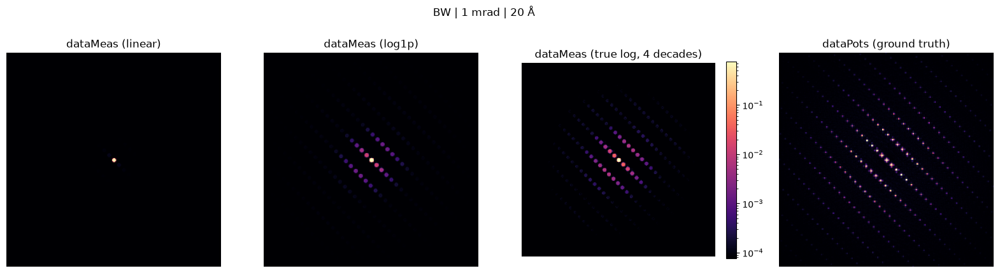

In [3]:
img, gt, probe = load_slice(1, 20)
print(f"dataMeas {img.shape}, min {img.min():.3g}, max {img.max():.3g}; disk radius {disk_radius(probe):.1f} px")

fig, axs = plt.subplots(1, 4, figsize=(20, 5))
axs[0].imshow(img, cmap="magma")
axs[0].set_title("dataMeas (linear)")
axs[1].imshow(np.log1p(img / img.max() * 1000), cmap="magma")
axs[1].set_title("dataMeas (log1p)")
im = axs[2].imshow(img, cmap="magma", norm=LogNorm(vmin=img.max() * 1e-4, vmax=img.max()))
axs[2].set_title("dataMeas (true log, 4 decades)")
fig.colorbar(im, ax=axs[2], fraction=0.046)
axs[3].imshow(gt, cmap="magma", vmax=np.percentile(gt, 99.9))  # clip the brightest pixels so the peaks are visible
axs[3].set_title("dataPots (ground truth)")
for ax in axs:
    ax.axis("off")
fig.suptitle(f"{material} | 1 mrad | 20 Å")
plt.show()

## 2. Ground truth

`dataPots` is a map, not a list of points, so the ground-truth spots are its **local maxima above 2 % of its maximum**, at least 3 px apart.

- The **central beam** (star) is the undiffracted beam, not a Bragg spot. It is left out of the ground truth, and predictions within 3 px of it are ignored in all scoring (`off_beam`).
- A spot is **visible** (blue ○) if the measured intensity within ±2 px reaches the display floor `max · 1e-4`, otherwise **not visible** (orange ✕). Many lattice positions carry almost no intensity in `dataMeas`, so no detector can be expected to find them.
- `dataPots` peaks between 1 and 2 % of the maximum (`weak`) are not ground truth. They are only used to describe false detections that sit just below the ground-truth threshold.

280 ground-truth spots (central beam excluded): 177 visible, 103 not visible


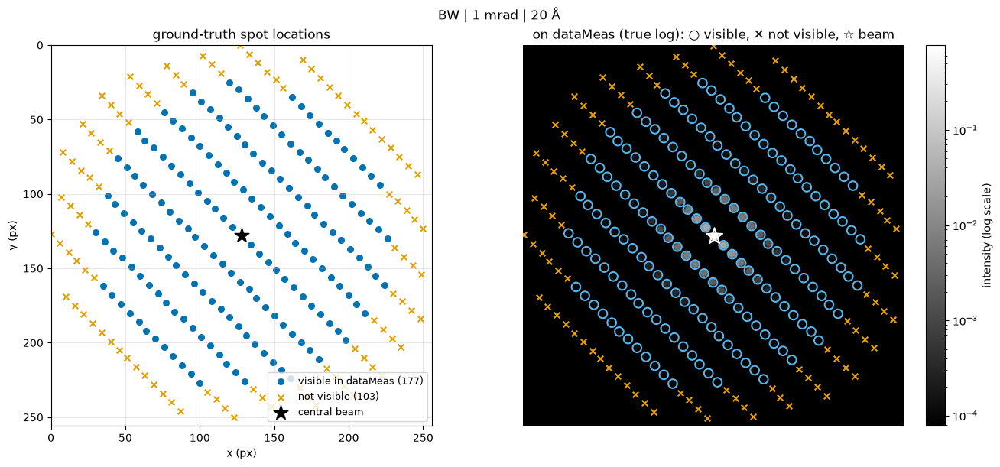

In [4]:
def off_beam(pts, centre, r=3):
    """True for points more than r px from the central beam."""
    return np.hypot(*(np.asarray(pts)[:, :2] - centre).T) > r


def ground_truth(img, gt):
    """Central-beam centre, ground-truth spots, their visibility in img, display floor, and weaker 1-2 % dataPots peaks."""
    beam = np.argwhere(img > img.max() / 2).mean(axis=0)
    points = peak_local_max(gt, min_distance=3, threshold_rel=0.02, exclude_border=False)  # (row, col) = (y, x)
    points = points[off_beam(points, beam)]
    floor = img.max() * 1e-4
    visible = maximum_filter(img, size=5)[points[:, 0], points[:, 1]] >= floor
    peaks_1pct = peak_local_max(gt, min_distance=3, threshold_rel=0.01, exclude_border=False)
    weak = peaks_1pct[gt[tuple(peaks_1pct.T)] < gt[tuple(points.T)].min()]
    return dict(beam=beam, points=points, visible=visible, floor=floor, weak=weak)


g = ground_truth(img, gt)
points, visible, beam = g["points"], g["visible"], g["beam"]
print(f"{len(points)} ground-truth spots (central beam excluded): {visible.sum()} visible, {(~visible).sum()} not visible")

fig, axs = plt.subplots(1, 2, figsize=(13, 6), constrained_layout=True)
ax = axs[0]
ax.scatter(points[visible, 1], points[visible, 0], s=30, marker="o", c=BLUE, label=f"visible in dataMeas ({visible.sum()})")
ax.scatter(points[~visible, 1], points[~visible, 0], s=30, marker="x", c=ORANGE, linewidths=1.5, label=f"not visible ({(~visible).sum()})")
ax.scatter(beam[1], beam[0], s=200, marker="*", c="k", label="central beam", zorder=3)
ax.set_xlim(0, gt.shape[1]); ax.set_ylim(gt.shape[0], 0)  # same orientation as the image
ax.set_aspect("equal")
ax.set_xlabel("x (px)"); ax.set_ylabel("y (px)")
ax.grid(alpha=0.3)
ax.legend(loc="lower right", fontsize=9)
ax.set_title("ground-truth spot locations")

ax = axs[1]
im = ax.imshow(img, cmap="gray", norm=LogNorm(vmin=g["floor"], vmax=img.max()))
ax.scatter(points[visible, 1], points[visible, 0], s=70, marker="o", facecolors="none", edgecolors=SKY, linewidths=1.5)
ax.scatter(points[~visible, 1], points[~visible, 0], s=30, marker="x", c=ORANGE, linewidths=1.5)
ax.scatter(beam[1], beam[0], s=250, marker="*", facecolors="none", edgecolors="white", linewidths=1.5)
fig.colorbar(im, ax=ax, fraction=0.046, label="intensity (log scale)")
ax.axis("off")
ax.set_title("on dataMeas (true log): ○ visible, ✕ not visible, ☆ beam")
fig.suptitle(f"{material} | 1 mrad | 20 Å")
plt.show()

## 3. Spotiflow model and scoring

**Model.** The `general` pretrained Spotiflow model was trained on fluorescence images (spatial transcriptomics, live-cell movies), not on diffraction data. It is downloaded automatically the first time. To use your own trained model, use the commented line instead. `get_model` loads the other pretrained models used in section 6.

**Scoring** (`score_spots`), the same for every run:

- predictions within 3 px of the central beam are ignored;
- each prediction is matched one-to-one to a ground-truth spot within `cutoff` = 3 px. Matched predictions are **found** (true positives), unmatched ground-truth spots are **missed**, unmatched predictions are **false detections**;
- all ground-truth spots count, visible or not, so a prediction on a real but faint spot is not counted as false. Found and missed spots are split into visible / not visible;
- false detections are split into **near a real spot** (a missed ground-truth spot 3–5 px away, i.e. a real disk whose centre was placed slightly off), **on a `dataPots` peak 1–2 %** (just below the ground-truth threshold) and **truly false** (nothing nearby). All of them count as false in precision and recall.

| marker | meaning |
|---|---|
| ○ light blue | found, visible |
| ◇ white | found, not visible |
| ✕ orange | missed, visible (drawn at the ground-truth position) |
| ⬡ light blue, dashed | false, near a real spot |
| □ orange | false, on a `dataPots` peak 1–2 % |
| △ yellow | false, truly false |

All other markers are drawn at the predicted positions. Missed spots that are not visible are not drawn.

Each result figure shows, from left to right: the measured pattern `dataMeas` (true log), the Spotiflow input (for ring correlation also the edge image), and the predictions drawn on `dataMeas`.

In [5]:
model = Spotiflow.from_pretrained("general")
# model = Spotiflow.from_folder("YOUR_MODEL_FOLDER_HERE")
MODELS = {"general": model}  # other pretrained models are loaded on first use (section 6)


def get_model(name):
    """A pretrained Spotiflow model by name, loaded once (downloaded the first time)."""
    if name not in MODELS:
        MODELS[name] = Spotiflow.from_pretrained(name)
    return MODELS[name]


def score_spots(img, gt, pred):
    """Match predictions to the ground truth and split them into the categories described above."""
    g = ground_truth(img, gt)
    pts, vis = g["points"], g["visible"]
    pred = pred[off_beam(pred, g["beam"])]
    m = points_matching(pts, pred, cutoff_distance=cutoff)
    gi = np.array([a for a, _ in m.matched_pairs], dtype=int)
    pj = np.array([b for _, b in m.matched_pairs], dtype=int)
    fp = np.array(m.false_positives, dtype=int)
    fn = np.array(m.false_negatives, dtype=int)
    m_off = points_matching(pts[fn], pred[fp], cutoff_distance=near_r)  # false, but 3-5 px from a missed spot
    rest = fp[list(m_off.false_positives)]
    m_weak = points_matching(g["weak"], pred[rest], cutoff_distance=cutoff)  # false, on a 1-2 % dataPots peak
    return dict(
        floor=g["floor"], n_gt=len(pts), n_vis=int(vis.sum()), n_pred=len(pred),
        found_vis=pred[pj[vis[gi]]], found_inv=pred[pj[~vis[gi]]],
        missed_vis=pts[fn[vis[fn]]], missed_inv=pts[fn[~vis[fn]]],
        fp_off=pred[fp[[b for _, b in m_off.matched_pairs]]],
        fp_near=pred[rest[[b for _, b in m_weak.matched_pairs]]],
        fp_false=pred[rest[list(m_weak.false_positives)]],
        precision=m.precision if len(pred) else np.nan, recall=m.recall,
    )


def summary_row(angle, thickness, s):
    """One row of a results table."""
    return dict(angle=f"{angle} mrad", thickness=f"{thickness} Å", gt=s["n_gt"], visible=s["n_vis"], predicted=s["n_pred"],
                found_vis=len(s["found_vis"]), found_not_vis=len(s["found_inv"]), missed_vis=len(s["missed_vis"]),
                false=len(s["fp_off"]) + len(s["fp_near"]) + len(s["fp_false"]), truly_false=len(s["fp_false"]),
                precision=round(s["precision"], 2), recall_vis=round(len(s["found_vis"]) / max(s["n_vis"], 1), 2),
                recall_all=round(s["recall"], 2))


MARKERS = [  # (key, label, scatter style)
    ("found_vis", "found, visible", dict(s=80, marker="o", facecolors="none", edgecolors=SKY, linewidths=1.5)),
    ("found_inv", "found, not visible", dict(s=80, marker="D", facecolors="none", edgecolors="white", linewidths=1.5)),
    ("missed_vis", "missed, visible", dict(s=35, marker="x", c=ORANGE, linewidths=1.5)),
    ("fp_off", f"false, near a real spot {cutoff}-{near_r} px", dict(s=110, marker="h", facecolors="none", edgecolors=SKY, linewidths=1.5, linestyles="--")),
    ("fp_near", "false, on dataPots peak 1-2%", dict(s=110, marker="s", facecolors="none", edgecolors=ORANGE, linewidths=1.8)),
    ("fp_false", "false, truly false", dict(s=90, marker="^", facecolors="none", edgecolors=YELLOW, linewidths=1.8)),
]


def plot_spots(img, s, title, panels=()):
    """The measured pattern (dataMeas, true log), optional Spotiflow-input panels (title, image), then the predictions on dataMeas."""
    n = len(panels) + 2
    fig, axs = plt.subplots(1, n, figsize=(6 * n, 6.5), constrained_layout=True, squeeze=False)
    axs = axs[0]
    axs[0].imshow(img, cmap="gray", norm=LogNorm(vmin=s["floor"], vmax=img.max()))
    axs[0].set_title("dataMeas (true log)")
    for ax, (panel_title, im) in zip(axs[1:], panels):
        ax.imshow(im, cmap="gray")
        ax.set_title(panel_title)
    ax = axs[-1]
    ax.imshow(img, cmap="gray", norm=LogNorm(vmin=s["floor"], vmax=img.max()))
    for key, label, style in MARKERS:
        if len(s[key]):
            ax.scatter(s[key][:, 1], s[key][:, 0], label=f"{label} ({len(s[key])})", **style)
    ax.legend(loc="lower right", fontsize=9, facecolor="0.2", labelcolor="white")
    ax.set_title(title)
    for ax in axs:
        ax.axis("off")
    plt.show()

## 4. One Spotiflow pipeline per angle (shared settings, 20 Å and 40 Å)

Spotiflow expects small, separate, blob-like spots, so the pattern is turned into something spot-like first. Which preprocessing works depends on the **overlap ratio** η = 2r / s, the disk diameter divided by the spacing between neighbouring spots (`main.pdf`, Eq. 1). On BW the spacing is s ≈ 8.5 px at every angle, but the disk radius r grows with the angle (2.6, 4.7 and 9.9 px).

| angle | η (BW) | disks | pipeline | settings |
|---|---|---|---|---|
| 1 mrad | 0.6 | separate | **log image → Spotiflow** | log ×1000, threshold 0.5 |
| 2 mrad | 1.1 | touching | **ring correlation → Spotiflow** | log ×10000, edge σ 0.5, threshold 0.5 |
| 4 mrad | 2.3 | overlapping | **ring correlation → Spotiflow** | log ×10000, edge σ 1, threshold 0.3 |

- **Log image**: `log1p(img / max · log_scale)` passed straight to Spotiflow.
- **Ring correlation** (Sobel rim matching, `main.pdf` Section 7): the Sobel edge magnitude of the smoothed log image (Gaussian σ = edge σ, central beam masked) is cross-correlated with the Sobel edges of the probe, i.e. a ring of radius r. When disks overlap their interiors blend, but each rim survives as an arc, and the correlation peaks where a full ring of edges is centred. A smaller edge σ at 2 mrad keeps the thin gaps between touching disks.

**How these were chosen.** Other Spotiflow inputs were tried on BW and did worse: the image shrunk 2× or 4× (0 spots at 2 and 4 mrad, because shrinking also shrinks the spacing), ring correlation at 1 mrad (42/177 visible: the ring is barely larger than the spot and blurs it), the log image convolved with the probe (same visible spots as the log image at 1 mrad, more false detections at 40 Å), the disk–ring filter of `main.pdf` Section 3 (32/176 at 2 mrad) and GCC-PHAT phase correlation (worst at every angle: whitening turns each disk into a needle-sharp peak that Spotiflow does not recognise). Spotiflow thresholds and edge σ were compared on 20 Å; the 2 mrad edge σ was also looked at on 40 Å, so the 40 Å rows are not fully held out.

In [6]:
SHARED = {  # angle: (method, settings); shared by all materials
    1: ("log",  dict(log_scale=1000, prob_thresh=0.5)),
    2: ("ring", dict(log_scale=10000, edge_sigma=0.5, prob_thresh=0.5)),  # thin edges keep the gaps between touching disks
    4: ("ring", dict(log_scale=10000, edge_sigma=1, prob_thresh=0.3)),
}


def detect(img, probe, method, log_scale, prob_thresh, edge_sigma=None, pmin=1, pmax=99.8, sf_scale=1, model_name="general"):
    """Build the Spotiflow input ("log" or "ring") and run Spotiflow on it. Returns (predictions, panels to plot).
    pmin / pmax: Spotiflow's normalizer percentiles (1 / 99.8 is Spotiflow's default); sf_scale: Spotiflow's resize factor;
    model_name: which pretrained Spotiflow model to use."""
    x = np.log1p(img / img.max() * log_scale)
    panels = [("Spotiflow input: log image", x)]
    if method == "ring":
        r = disk_radius(probe)
        cy, cx = np.argwhere(img > img.max() / 2).mean(axis=0)  # central beam
        yy, xx = np.indices(img.shape)
        edges = sobel(gaussian_filter(x, edge_sigma)) * (np.hypot(yy - cy, xx - cx) > r + 3)  # central beam masked
        ring = sobel(gaussian_filter(probe.astype(float), edge_sigma))  # template: edges of the probe = ring of radius r
        F = np.fft.fft2(edges) * np.conj(np.fft.fft2(np.fft.ifftshift(ring)))  # ring centred in its array -> shift to the origin
        x = np.clip(np.real(np.fft.ifft2(F)), 0, None)
        panels = [("1) edge image (central beam masked)", edges), ("2) Spotiflow input: ring correlation", x)]
    # Spotiflow does not support sub-pixel localisation when it rescales the image
    kw = dict(subpix=True) if sf_scale == 1 else dict(subpix=False, scale=sf_scale)
    pred, _ = get_model(model_name).predict(x, min_distance=3, prob_thresh=prob_thresh, normalizer=lambda im: normalize(im, pmin, pmax), **kw)
    return pred, panels


def run_all(settings, label):
    """Detect and score every angle at 20 and 40 Å. Returns the results table and the runs (for plotting)."""
    rows, runs = [], {}
    for thickness in [20, 40]:
        for angle, (method, kw) in settings.items():
            img_t, gt_t, probe_t = load_slice(angle, thickness)
            pred, panels = detect(img_t, probe_t, method, **kw)
            s = score_spots(img_t, gt_t, pred)
            runs[(angle, thickness)] = (img_t, s, panels)
            rows.append(summary_row(angle, thickness, s))
    table = pd.DataFrame(rows).set_index(["angle", "thickness"]).sort_index()
    print(f"{material}: {label}; ground truth = dataPots peaks > 2% of max (central beam excluded), cutoff = {cutoff} px\n")
    print(table.to_string())
    return table, runs


def plot_runs(runs, settings, label):
    for (angle, thickness), (img_t, s, panels) in sorted(runs.items()):
        method, kw = settings[angle]
        rec_vis = len(s["found_vis"]) / max(s["n_vis"], 1)
        plot_spots(img_t, s, f"{material} | {angle} mrad | {thickness} Å | {label}: {method}, "
                             + ", ".join(f"{k} {v}" for k, v in kw.items())
                             + f"\nprecision {s['precision']:.2f}, recall {s['recall']:.2f} (visible: {rec_vis:.2f})", panels)


shared_table, shared_runs = run_all(SHARED, "shared settings")

BW: shared settings; ground truth = dataPots peaks > 2% of max (central beam excluded), cutoff = 3 px

                   gt  visible  predicted  found_vis  found_not_vis  missed_vis  false  truly_false  precision  recall_vis  recall_all
angle  thickness                                                                                                                      
1 mrad 20 Å       280      177        213        177             36           0      0            0       1.00        1.00        0.76
       40 Å       280      270        278        269              4           1      5            0       0.98        1.00        0.98
2 mrad 20 Å       280      176         44         41              0         135      3            3       0.93        0.23        0.15
       40 Å       282      255        103        100              0         155      3            3       0.97        0.39        0.35
4 mrad 20 Å       282      132         22         17              0         115      5 

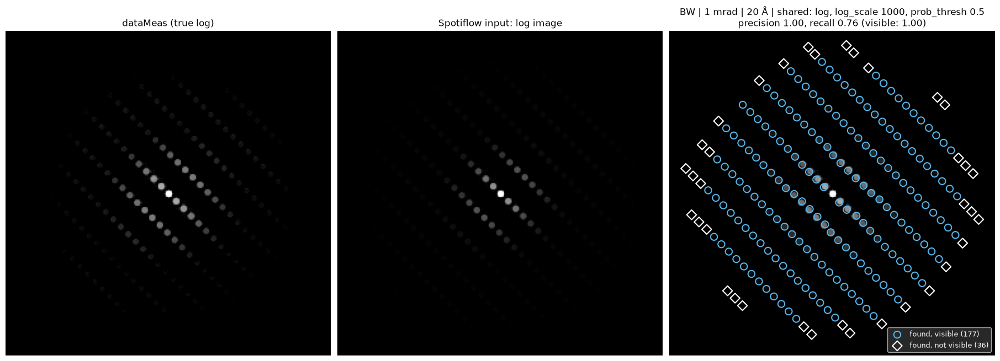

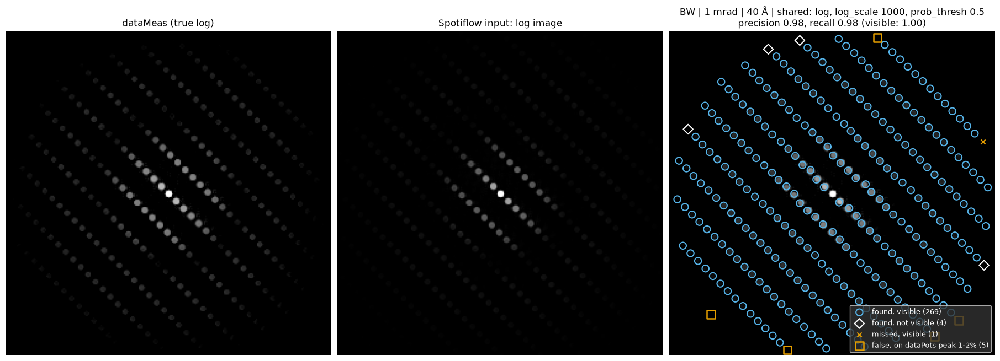

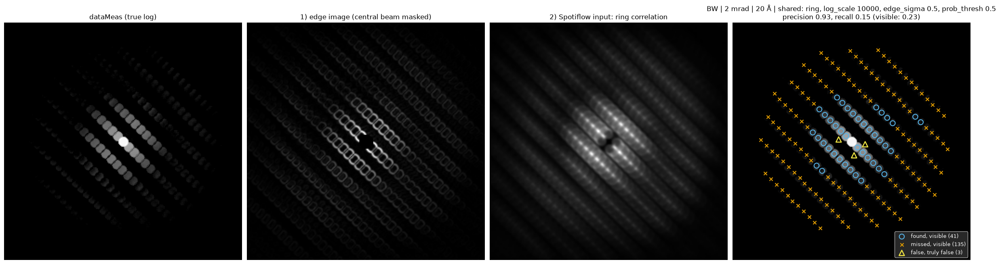

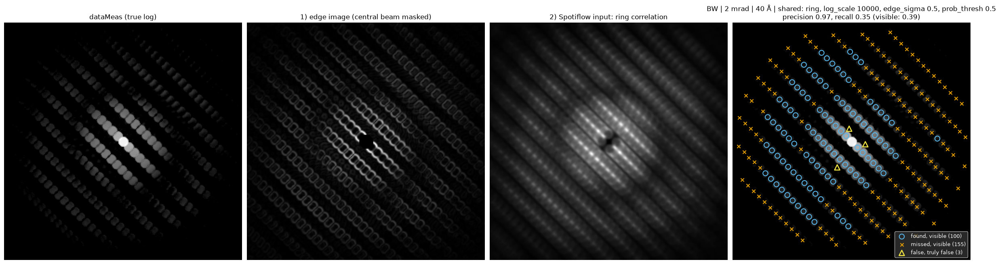

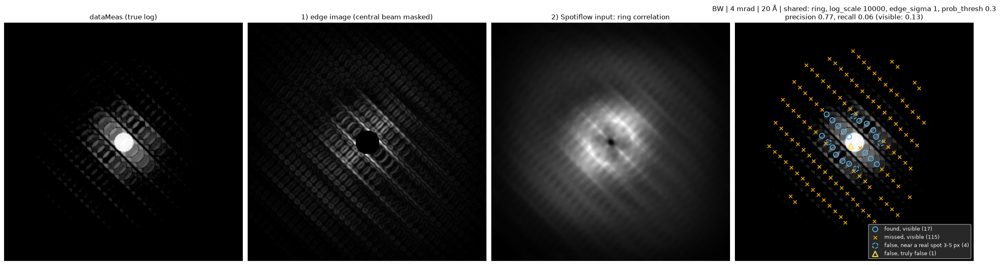

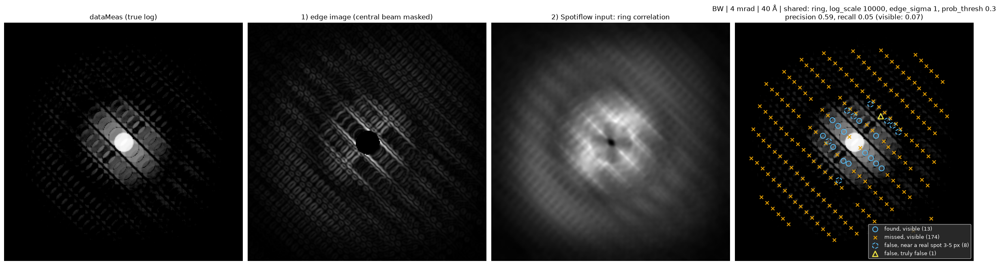

In [7]:
plot_runs(shared_runs, SHARED, "shared")

## 5. BW-tuned settings

Same pipelines, but every setting was searched **on BW at 40 Å** to find the best values for this material:

- log scale, edge σ, Spotiflow threshold and `min_distance`;
- correlation power (1 = cross-correlation … 0.3, close to phase correlation): 1 was best everywhere;
- Spotiflow's normalizer percentiles (`pmin`, `pmax`): 1 / 99 instead of the default 1 / 99.8 at 2 and 4 mrad;
- Spotiflow's `scale` (0.5, 1, 2: the image is resized before prediction). 2× helps at 4 mrad, but adds many false detections.

| angle | method | log scale | edge σ | normalizer | threshold |
|---|---|---|---|---|---|
| 1 mrad | log image → Spotiflow | 100 | – | 1 / 99.8 (default) | 0.15 |
| 2 mrad | ring correlation → Spotiflow | 100000 | 0.5 | 1 / 99 | 0.5 |
| 4 mrad | ring correlation → Spotiflow | 100000 | 0.5 | 1 / 99 | 0.02 |

At 4 mrad the most spots are found with Spotiflow `sf_scale = 2` and normalizer 5 / 99.8 (about half of the visible spots), but more than half of those detections are false. The table uses the setting that keeps precision ≥ 0.8; the other one is commented out in `TUNED_BW`.

**Result.** At 2 and 4 mrad the tuned settings find several times more visible spots than the shared ones, also at **20 Å, which was not used for tuning and is the fair check** (2 mrad: 151 vs 41 of 176; 4 mrad: 39 vs 17 of 132). The price at 2 mrad, 20 Å is more false detections (26 vs 3, precision 0.88 vs 0.93). At 1 mrad the shared settings are as good or better.

**Caveats.** The 40 Å rows are optimistic, because that is where the settings were tuned. The values are BW-specific: on Co₃(O₂F)₂ they give more false detections than the shared settings (e.g. 4 mrad: precision 0.50).

In [8]:
TUNED_BW = {  # angle: (method, settings); tuned on BW at 40 Å
    1: ("log",  dict(log_scale=100, prob_thresh=0.15)),
    2: ("ring", dict(log_scale=100000, edge_sigma=0.5, prob_thresh=0.5, pmin=1, pmax=99)),
    4: ("ring", dict(log_scale=100000, edge_sigma=0.5, prob_thresh=0.02, pmin=1, pmax=99)),
    # 4: ("ring", dict(log_scale=100000, edge_sigma=0.5, prob_thresh=0.02, pmin=5, pmax=99.8, sf_scale=2)),  # ~3x more spots at 40 Å, but more than half false
}

if material != "BW":
    print(f"Note: TUNED_BW was tuned on BW, but the current material is {material}.\n")

tuned_table, tuned_runs = run_all(TUNED_BW, "BW-tuned settings")

cols = ["predicted", "found_vis", "false", "precision", "recall_vis"]
comparison = pd.concat({"shared": shared_table[cols], "BW-tuned": tuned_table[cols]}, axis=1)
comparison.insert(0, ("", "visible"), shared_table["visible"])
print(f"\n{material}: shared vs BW-tuned settings (tuned on 40 Å; 20 Å is the fair check)\n")
print(comparison.to_string())

BW: BW-tuned settings; ground truth = dataPots peaks > 2% of max (central beam excluded), cutoff = 3 px

                   gt  visible  predicted  found_vis  found_not_vis  missed_vis  false  truly_false  precision  recall_vis  recall_all
angle  thickness                                                                                                                      
1 mrad 20 Å       280      177        172        168              3           9      1            1       0.99        0.95        0.61
       40 Å       280      270        274        269              3           1      2            1       0.99        1.00        0.97
2 mrad 20 Å       280      176        212        151             35          25     26           25       0.88        0.86        0.66
       40 Å       282      255        221        199             12          56     10            3       0.95        0.78        0.75
4 mrad 20 Å       282      132         59         39             10          93     1

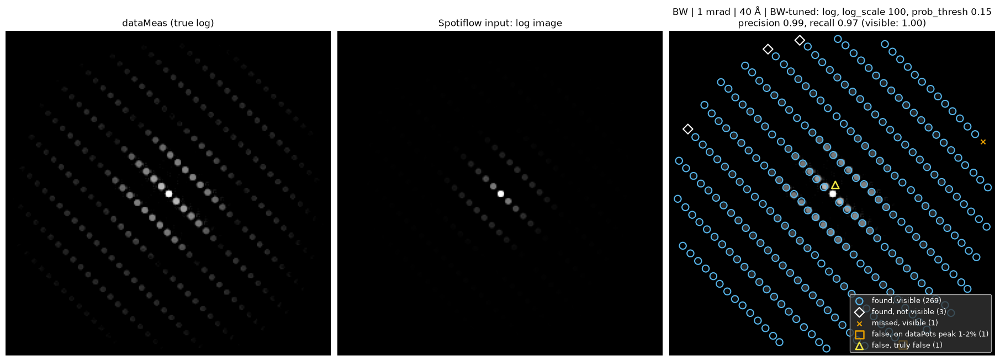

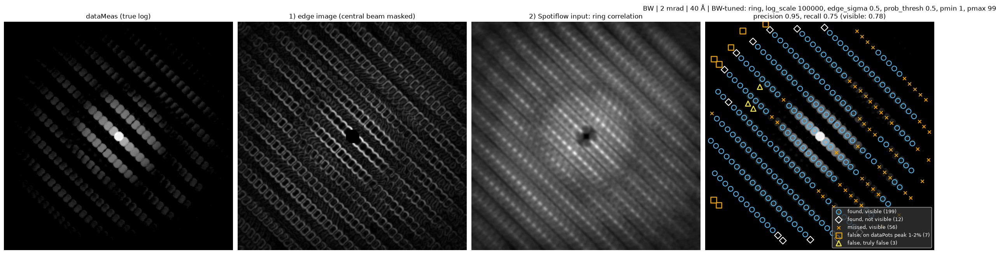

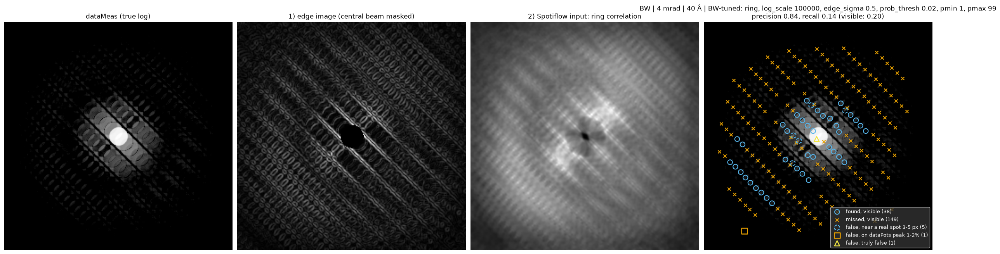

In [9]:
plot_runs({k: v for k, v in tuned_runs.items() if k[1] == 40}, TUNED_BW, "BW-tuned")

## 6. Other pretrained Spotiflow models

Spotiflow ships several pretrained 2D models besides `general`: `hybiss` (spatial transcriptomics), `fluo_live` (live-cell fluorescence) and `synth_complex` (synthetic spots). Each was trained on different spot sizes and backgrounds, so each responds differently to the ring-correlation map. With the BW-tuned inputs (log ×100000, edge σ 0.5, normalizer 1 / 99), each model was run at several thresholds:

- **2 mrad: `hybiss`, threshold 0.5.** More spots and fewer false detections than `general` at 20 Å, but more false detections at 40 Å, so it is a trade-off rather than a clear improvement.
- **4 mrad: `fluo_live`, threshold 0.1.** About as good as `general` at 20 Å and about a quarter more visible spots at 40 Å, at the same precision. At threshold 0.02 it finds the most spots of any setting tried (`fluo_live_low` in the comment), but about 30 % of those detections are false.
- `synth_complex` finds almost nothing at either angle, and `min_distance` (1–3) and `peak_mode` (`fast` / `skimage`) had no effect.
- 1 mrad keeps `general` with the shared settings (section 4), which already finds every visible spot; other models were not tried there.

**Caveats.** Thresholds were compared on both 20 and 40 Å, so neither thickness is held out, and only BW was tested. Choosing a model only changes how a fluorescence-trained model reads a preprocessed image. To learn what overlapping diffraction disks look like, Spotiflow would need to be fine-tuned on this data (`dataMeas` or the ring-correlation map as input, `dataPots` peaks as points).

In [10]:
MODEL_CHOICE = {  # angle: (method, settings); BW-tuned inputs with the pretrained model that suited each angle best
    1: SHARED[1],
    2: ("ring", dict(log_scale=100000, edge_sigma=0.5, prob_thresh=0.5, pmin=1, pmax=99, model_name="hybiss")),
    4: ("ring", dict(log_scale=100000, edge_sigma=0.5, prob_thresh=0.1, pmin=1, pmax=99, model_name="fluo_live")),
    # 4: ("ring", dict(log_scale=100000, edge_sigma=0.5, prob_thresh=0.02, pmin=1, pmax=99, model_name="fluo_live")),  # fluo_live_low: most spots, ~30% false
}

model_table, model_runs = run_all(MODEL_CHOICE, "pretrained model per angle")

comparison_models = pd.concat({"BW-tuned (general)": tuned_table[cols], "model per angle": model_table[cols]}, axis=1)
comparison_models.insert(0, ("", "visible"), tuned_table["visible"])
print(f"\n{material}: BW-tuned settings with the general model vs a pretrained model per angle\n")
print(comparison_models.to_string())

BW: pretrained model per angle; ground truth = dataPots peaks > 2% of max (central beam excluded), cutoff = 3 px

                   gt  visible  predicted  found_vis  found_not_vis  missed_vis  false  truly_false  precision  recall_vis  recall_all
angle  thickness                                                                                                                      
1 mrad 20 Å       280      177        213        177             36           0      0            0       1.00        1.00        0.76
       40 Å       280      270        278        269              4           1      5            0       0.98        1.00        0.98
2 mrad 20 Å       280      176        214        161             44          15      9            9       0.96        0.91        0.73
       40 Å       282      255        253        206             14          49     33           26       0.87        0.81        0.78
4 mrad 20 Å       282      132         56         36             13         

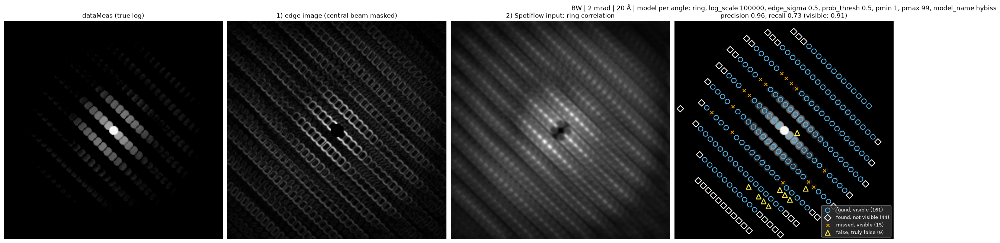

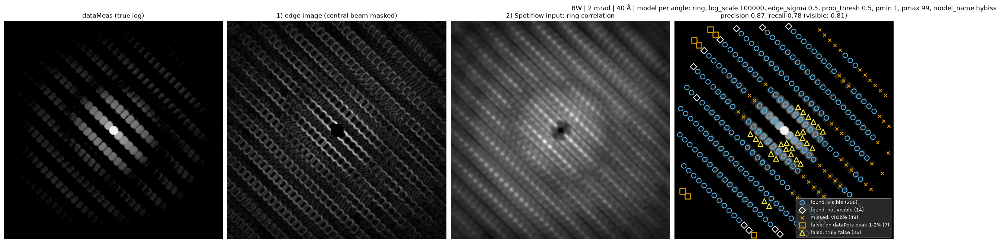

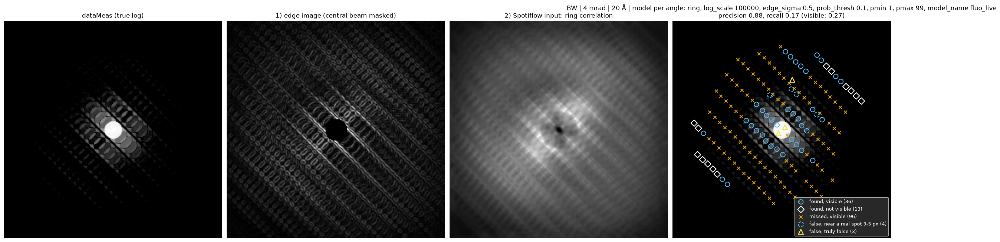

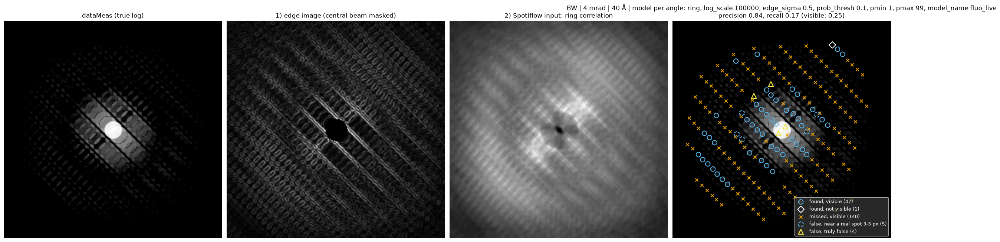

In [11]:
plot_runs({k: v for k, v in model_runs.items() if k[0] != 1}, MODEL_CHOICE, "model per angle")